# 01 · Exploratory Data Analysis (EDA)
## Estimasi Harga Rumah California dengan MLP Regresi

Notebook ini memeriksa dataset **California Housing Prices** sebelum dilakukan preprocessing dan pemodelan.
Tujuan EDA: memahami distribusi target, sebaran dan kualitas tiap fitur, hubungan antarfitur, lalu menyimpulkan
**keputusan preprocessing** yang akan dipakai di notebook berikutnya.

**Tugas model:** regresi, memprediksi `median_house_value` (median harga rumah per blok sensus, dalam USD).

### Isi notebook

| Bagian | Isi |
|---|---|
| 1 | Gambaran umum dataset: ukuran, tipe data, nilai kosong, duplikat, statistik ringkas |
| 2 | Distribusi label (target `median_house_value`; proyek ini regresi, jadi labelnya kontinu) |
| 3 | Histogram fitur numerik, skewness, outlier, efek `log1p`, dan sebaran fitur kategorikal |
| 4 | Korelasi antarfitur dan hubungan fitur dengan target |
| 5 | Temuan penting dari EDA yang memengaruhi preprocessing |

In [1]:
import sys, os, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/california-house-price-mlp"):
        subprocess.run(["git", "clone", "https://github.com/lukito789/california-house-price-mlp.git"],
                       cwd="/content", check=True)
    os.chdir("/content/california-house-price-mlp/notebooks")

## 0. Setup

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Notebook ini bisa dijalankan dari folder notebooks/ maupun dari folder utama proyek
ROOT = Path.cwd()
if not (ROOT / "data" / "housing.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "housing.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


TARGET = "median_house_value"
CAT_FEATURE = "ocean_proximity"
NUM_FEATURES = [
    "longitude", "latitude", "housing_median_age", "total_rooms",
    "total_bedrooms", "population", "households", "median_income",
]
print("Dataset :", DATA_PATH)
print("Grafik  :", FIG_DIR)

Dataset : /content/california-house-price-mlp/data/housing.csv
Grafik  : /content/california-house-price-mlp/reports/figures


## 1. Gambaran Umum Dataset

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")
display(df.head())

Jumlah baris : 20,640
Jumlah kolom : 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
info = pd.DataFrame({
    "tipe": df.dtypes.astype(str),
    "nilai_kosong": df.isna().sum(),
    "persen_kosong": (df.isna().mean() * 100).round(2),
    "nilai_unik": df.nunique(),
})
display(info)
print("Baris duplikat:", df.duplicated().sum())

,tipe,nilai_kosong,persen_kosong,nilai_unik
longitude,float64,0,0.0,844
latitude,float64,0,0.0,862
housing_median_age,float64,0,0.0,52
total_rooms,float64,0,0.0,5926
total_bedrooms,float64,207,1.0,1923
population,float64,0,0.0,3888
households,float64,0,0.0,1815
median_income,float64,0,0.0,12928
median_house_value,float64,0,0.0,3842
ocean_proximity,object,0,0.0,5


Baris duplikat: 0


In [ ]:
display(df[NUM_FEATURES + [TARGET]].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


**Catatan:** satu baris adalah satu *blok sensus* (kelompok wilayah kecil), bukan satu rumah. Karena itu `total_rooms`,
`total_bedrooms`, `population`, dan `households` adalah total untuk seluruh blok. Hanya `total_bedrooms` yang memiliki nilai kosong,
dan tidak ada baris duplikat.

## 2. Distribusi Label (Target)

Proyek ini adalah **regresi**, sehingga labelnya berupa angka kontinu (`median_house_value`), bukan kelas. Maka yang diperiksa
adalah bentuk distribusinya, kemiringannya, dan adanya nilai yang terpotong.

count     20640.0
mean     206856.0
std      115396.0
min       14999.0
25%      119600.0
50%      179700.0
75%      264725.0
max      500001.0

Skewness : 0.98
Nilai maksimum $500,001 muncul pada 965 baris (4.68%)


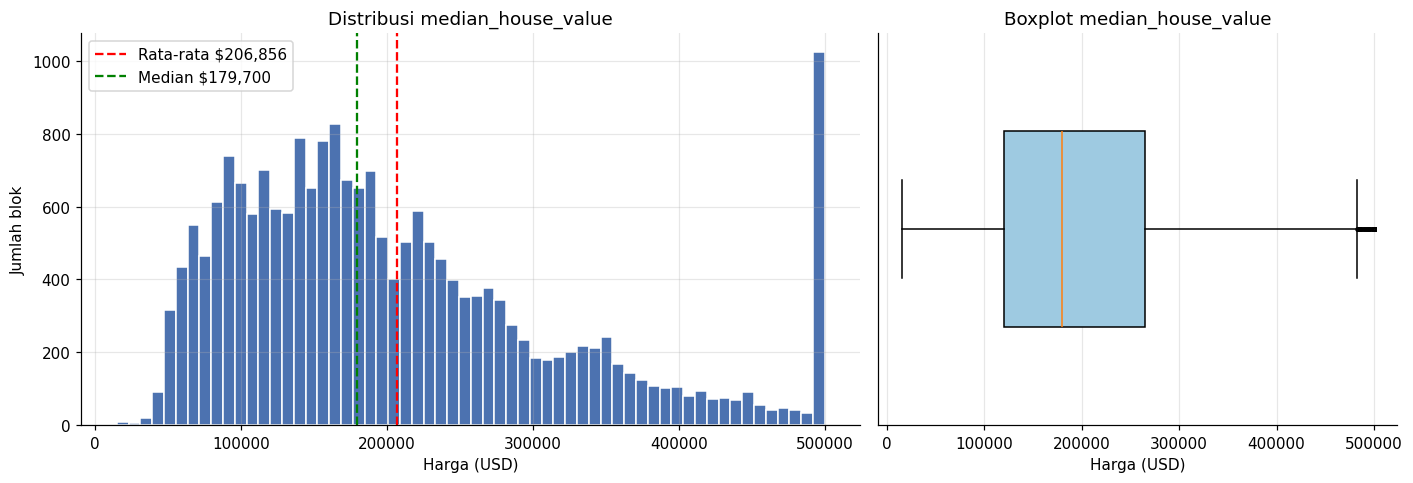

In [ ]:
y = df[TARGET]
print(y.describe().round(0).to_string())
print(f"\nSkewness : {y.skew():.2f}")

cap = y.max()
n_cap = int((y == cap).sum())
print(f"Nilai maksimum ${cap:,.0f} muncul pada {n_cap:,} baris ({n_cap / len(y) * 100:.2f}%)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 2]})

ax[0].hist(y, bins=60, color="#4C72B0", edgecolor="white")
ax[0].axvline(y.mean(), color="red", ls="--", label=f"Rata-rata ${y.mean():,.0f}")
ax[0].axvline(y.median(), color="green", ls="--", label=f"Median ${y.median():,.0f}")
ax[0].set(title="Distribusi median_house_value", xlabel="Harga (USD)", ylabel="Jumlah blok")
ax[0].legend()

ax[1].boxplot(y, vert=False, widths=0.5, patch_artist=True,
              boxprops={"facecolor": "#9ecae1"}, flierprops={"markersize": 2, "alpha": 0.4})
ax[1].set(title="Boxplot median_house_value", xlabel="Harga (USD)", yticks=[])

plt.tight_layout()
save_fig("01_distribusi_target")
plt.show()

**Temuan:** distribusi target miring ke kanan (skewness ≈ 0,98): rata-rata lebih tinggi daripada median.
Ada **lonjakan di ujung kanan**: 965 blok (4,68%) bernilai tepat \$500.001. Itu bukan harga sebenarnya, melainkan **batas atas
(*capping*) saat data dikumpulkan**. Akibatnya, model tidak pernah melihat harga di atas angka itu dan cenderung kesulitan pada
blok yang sangat mahal. Ini perlu dicatat sebagai keterbatasan.

## 3. Histogram Fitur Numerik

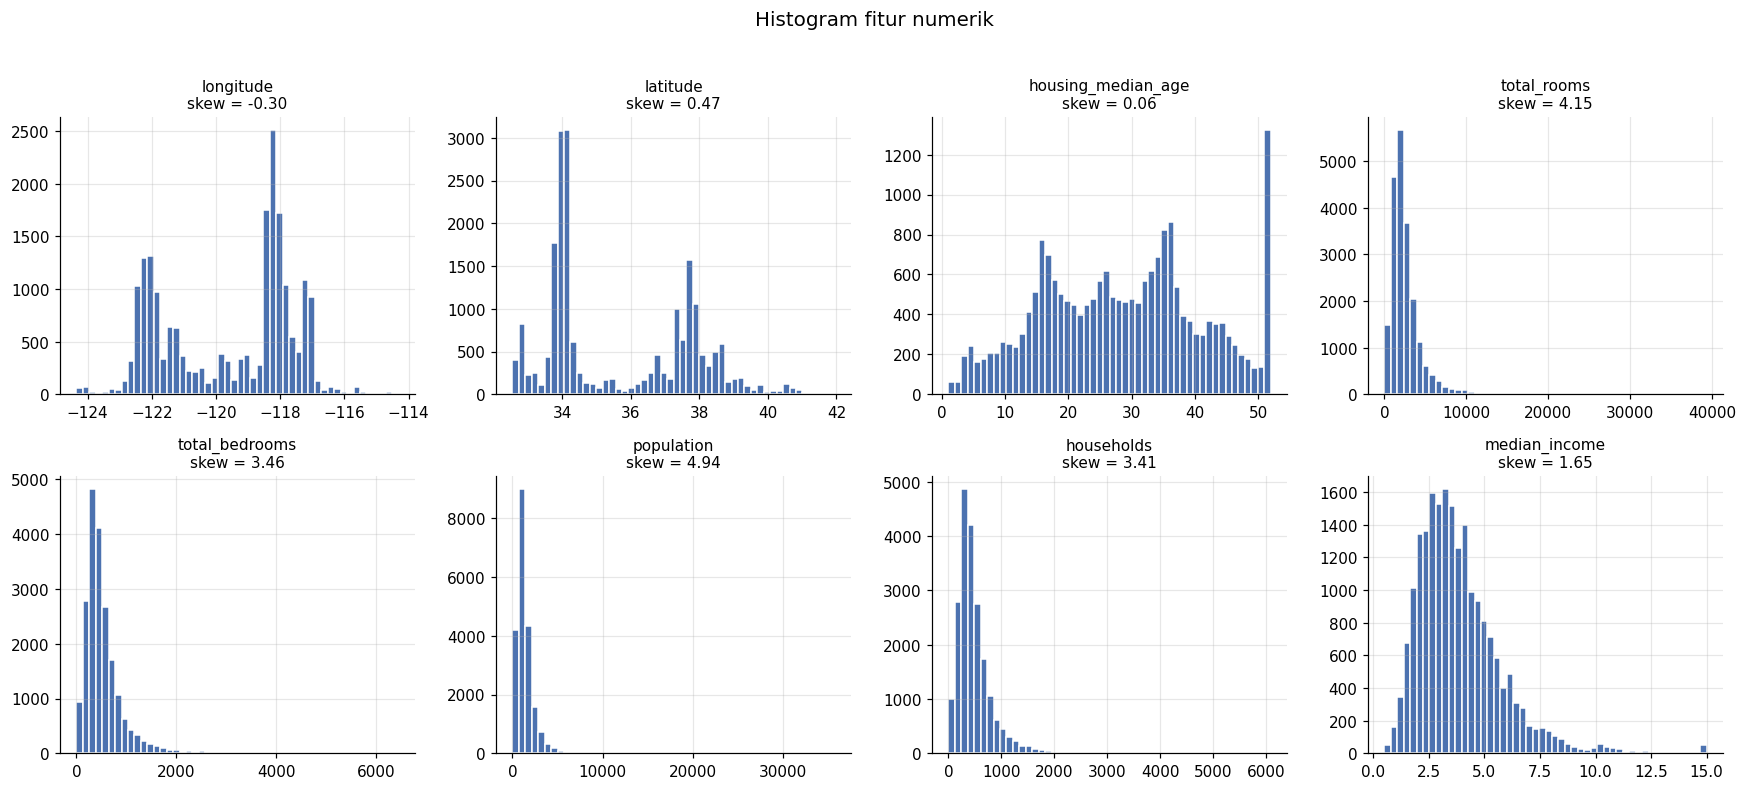

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUM_FEATURES):
    ax.hist(df[col].dropna(), bins=50, color="#4C72B0", edgecolor="white")
    ax.set_title(f"{col}\nskew = {df[col].skew():.2f}", fontsize=10)
fig.suptitle("Histogram fitur numerik", fontsize=13, y=1.02)
plt.tight_layout()
save_fig("02_histogram_fitur_numerik")
plt.show()

In [ ]:
rows = []
for col in NUM_FEATURES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
    rows.append({"fitur": col, "skewness": df[col].skew(),
                 "outlier_IQR": n_out, "persen_outlier": n_out / len(df) * 100})
display(pd.DataFrame(rows).set_index("fitur").round(2))

,skewness,outlier_IQR,persen_outlier
fitur,,,
longitude,-0.30,0,0.00
latitude,0.47,0,0.00
housing_median_age,0.06,0,0.00
total_rooms,4.15,1287,6.24
total_bedrooms,3.46,1271,6.16
population,4.94,1196,5.79
households,3.41,1220,5.91
median_income,1.65,681,3.30


**Temuan:**
- Empat fitur hitungan (`total_rooms`, `total_bedrooms`, `population`, `households`) **sangat miring ke kanan** (skewness 3,4 sampai 4,9)
  dengan sekitar 1.200 sampai 1.300 outlier per fitur menurut aturan IQR (sekitar 6% baris). Blok yang sangat besar memang ada dan valid, jadi
  outlier ini **tidak dihapus** melainkan diredam lewat transformasi.
- `housing_median_age`, `longitude`, dan `latitude` relatif simetris. `latitude` dan `longitude` bimodal karena penduduk California
  terkonsentrasi di dua area (Bay Area dan Los Angeles).
- `housing_median_age` menumpuk di nilai 52 (batas atas data).
- `median_income` miring ke kanan sedang (skewness 1,65) dan sedikit menumpuk di nilai maksimum 15.

Berikut efek transformasi `log1p` pada keempat fitur hitungan.

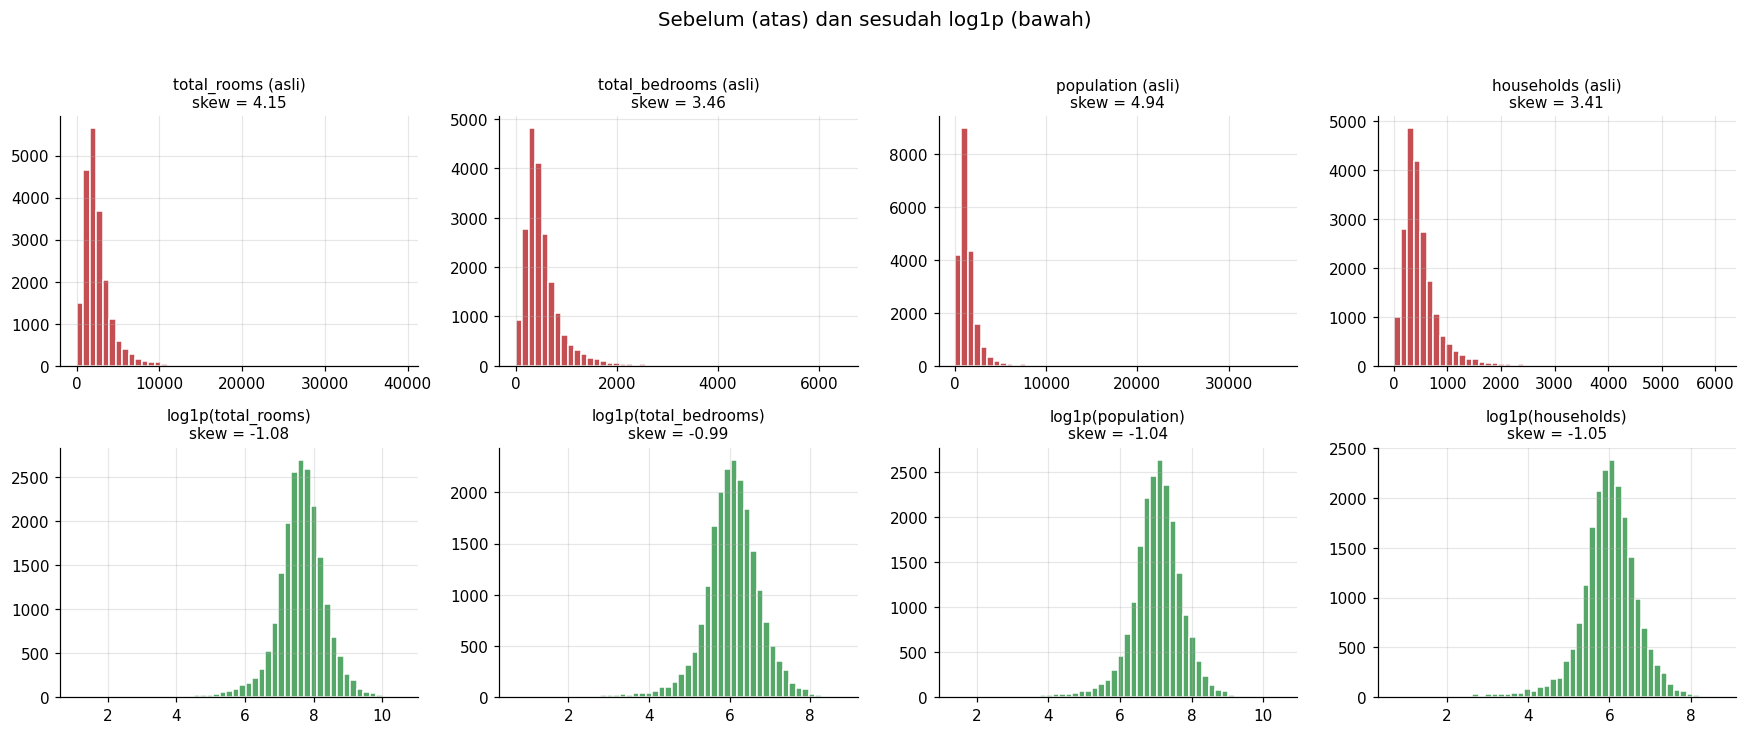

In [ ]:
SKEWED = ["total_rooms", "total_bedrooms", "population", "households"]

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for i, col in enumerate(SKEWED):
    axes[0, i].hist(df[col].dropna(), bins=50, color="#C44E52", edgecolor="white")
    axes[0, i].set_title(f"{col} (asli)\nskew = {df[col].skew():.2f}", fontsize=10)

    log_vals = np.log1p(df[col].dropna())
    axes[1, i].hist(log_vals, bins=50, color="#55A868", edgecolor="white")
    axes[1, i].set_title(f"log1p({col})\nskew = {log_vals.skew():.2f}", fontsize=10)

fig.suptitle("Sebelum (atas) dan sesudah log1p (bawah)", fontsize=13, y=1.02)
plt.tight_layout()
save_fig("03_efek_log1p")
plt.show()

Setelah `log1p`, skewness turun dari kisaran 3,4 sampai 4,9 menjadi sekitar −1. Distribusi jauh lebih mendekati simetris
(sedikit miring ke kiri), jadi transformasi ini layak dipakai.

**Fitur kategorikal `ocean_proximity`:**

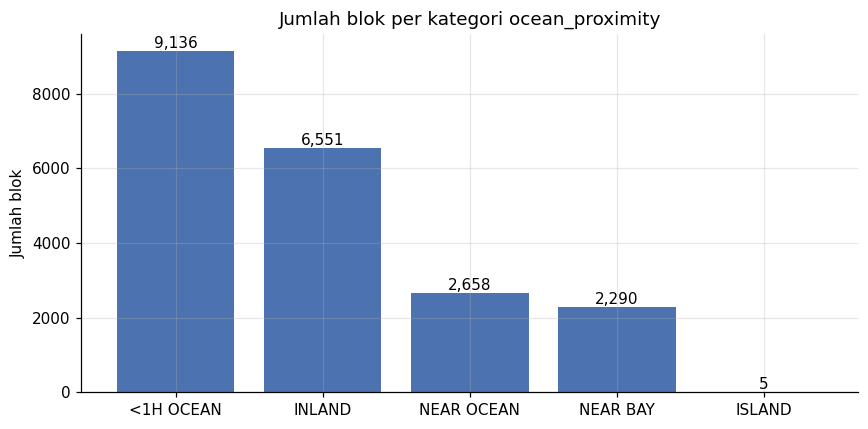

In [ ]:
counts = df[CAT_FEATURE].value_counts()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values, color="#4C72B0")
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values])
ax.set(title="Jumlah blok per kategori ocean_proximity", ylabel="Jumlah blok")
plt.tight_layout()
save_fig("04_sebaran_ocean_proximity")
plt.show()

Kategori `ISLAND` hanya berisi **5 baris**. Sangat sedikit untuk dipelajari model, tetapi tetap dipertahankan (di-*one-hot*)
supaya semua kategori asli dataset tetap terwakili.

## 4. Korelasi Antarfitur

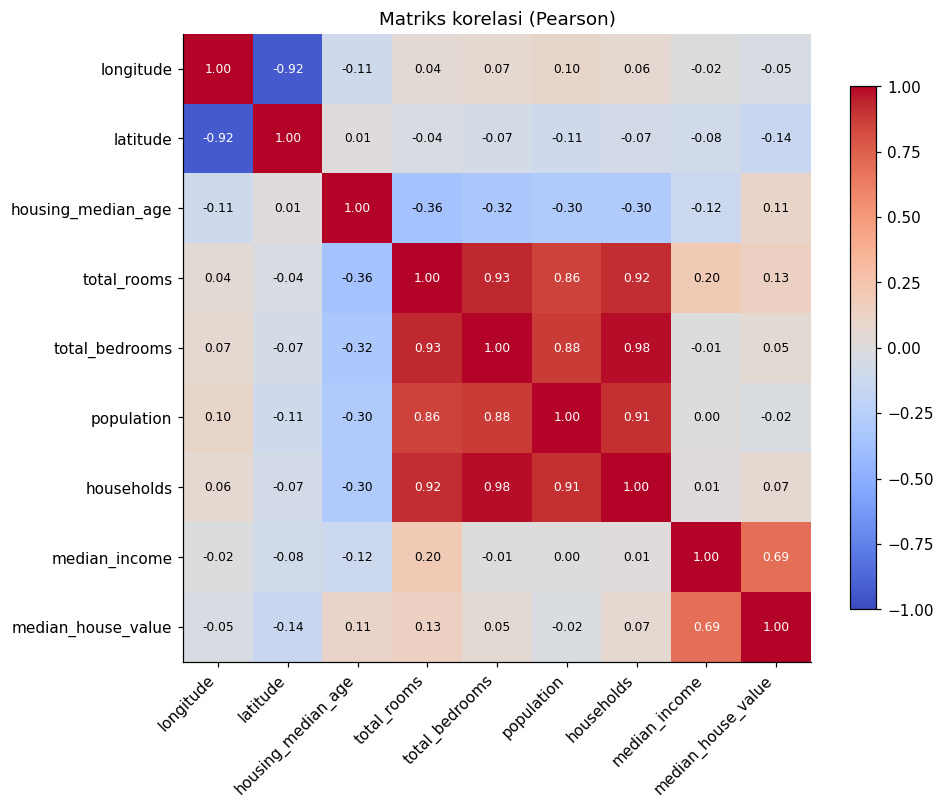

In [ ]:
corr = df[NUM_FEATURES + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im, shrink=0.8)
ax.set_title("Matriks korelasi (Pearson)")
plt.tight_layout()
save_fig("05_heatmap_korelasi")
plt.show()

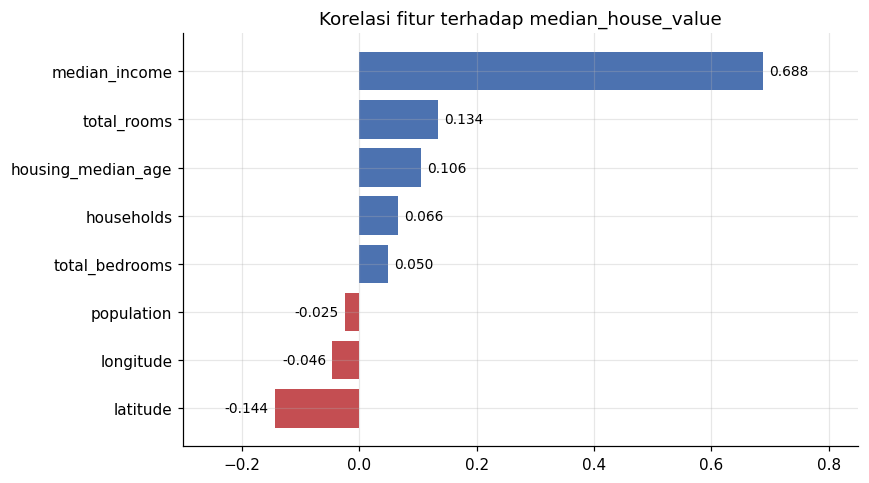

In [ ]:
target_corr = corr[TARGET].drop(TARGET).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(target_corr.index, target_corr.values,
        color=["#C44E52" if v < 0 else "#4C72B0" for v in target_corr.values])
for i, v in enumerate(target_corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.3f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set(title="Korelasi fitur terhadap median_house_value", xlim=(-0.3, 0.85))
plt.tight_layout()
save_fig("06_korelasi_terhadap_target")
plt.show()

In [ ]:
# Pasangan fitur dengan |korelasi| >= 0.8 (indikasi multikolinearitas)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().reset_index()
pairs.columns = ["fitur_1", "fitur_2", "korelasi"]
pairs = pairs[pairs["korelasi"].abs() >= 0.8].sort_values("korelasi", key=abs, ascending=False)
display(pairs.round(3).reset_index(drop=True))

,fitur_1,fitur_2,korelasi
0,total_bedrooms,households,0.980
1,total_rooms,total_bedrooms,0.930
2,longitude,latitude,-0.925
3,total_rooms,households,0.918
4,population,households,0.907
5,total_bedrooms,population,0.878
6,total_rooms,population,0.857


**Temuan:**
- `median_income` adalah prediktor terkuat (r ≈ 0,69). Fitur lain berkorelasi lemah secara linear dengan target
  (|r| ≤ 0,15). Hubungan lokasi dengan harga tidak linear, jadi korelasi Pearson meremehkannya, dan ini salah satu alasan memakai MLP.
- Keempat fitur hitungan **saling berkorelasi sangat tinggi** (r 0,86 sampai 0,98), karena semuanya mengukur "ukuran blok".
  `latitude` dan `longitude` juga berkorelasi kuat (r ≈ −0,93) karena bentuk garis pantai California.
- Multikolinearitas ini tidak merusak MLP seperti pada regresi linear, tetapi membuat informasinya redundan.

**Hubungan fitur penting dengan target:**

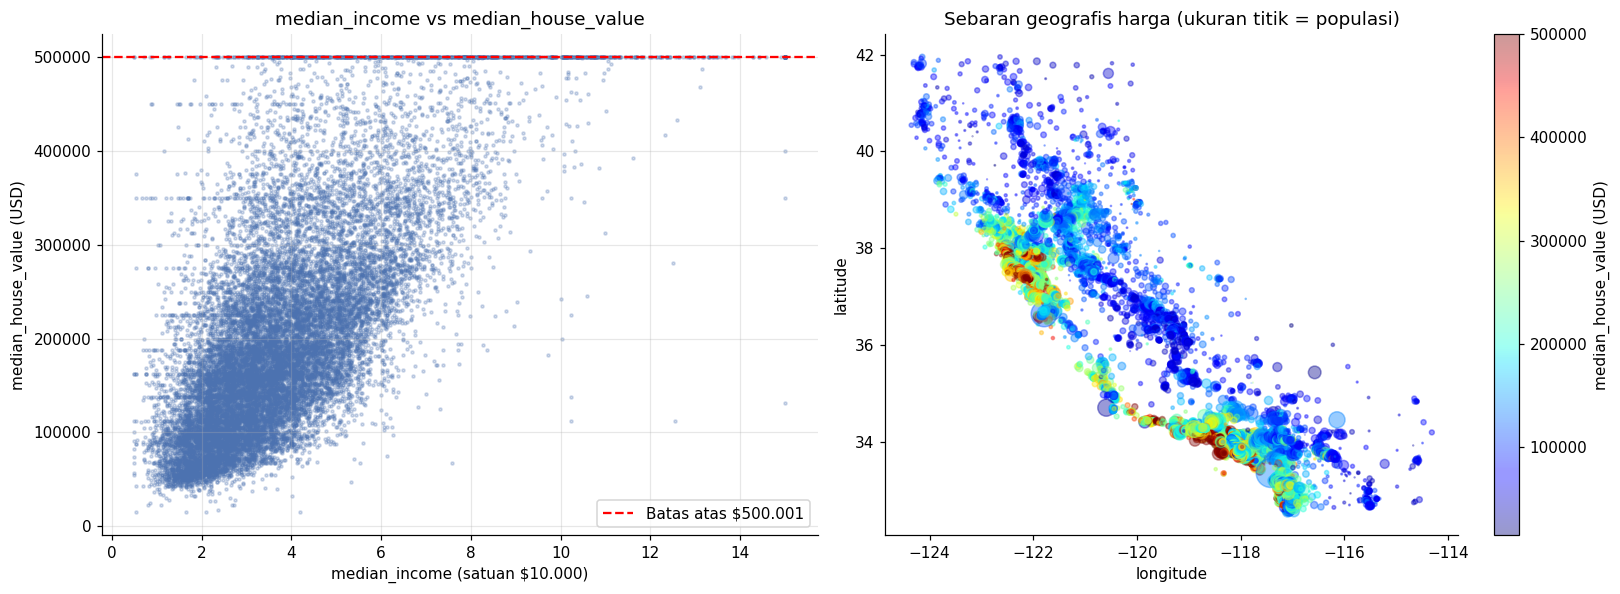

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(df["median_income"], df[TARGET], s=4, alpha=0.25, color="#4C72B0")
axes[0].axhline(500001, color="red", ls="--", label="Batas atas $500.001")
axes[0].set(title="median_income vs median_house_value",
            xlabel="median_income (satuan $10.000)", ylabel="median_house_value (USD)")
axes[0].legend(loc="lower right")

sc = axes[1].scatter(df["longitude"], df["latitude"], c=df[TARGET], s=df["population"] / 100,
                     alpha=0.4, cmap="jet")
fig.colorbar(sc, ax=axes[1], label="median_house_value (USD)")
axes[1].set(title="Sebaran geografis harga (ukuran titik = populasi)",
            xlabel="longitude", ylabel="latitude")
axes[1].grid(False)

plt.tight_layout()
save_fig("07_income_dan_peta_harga")
plt.show()

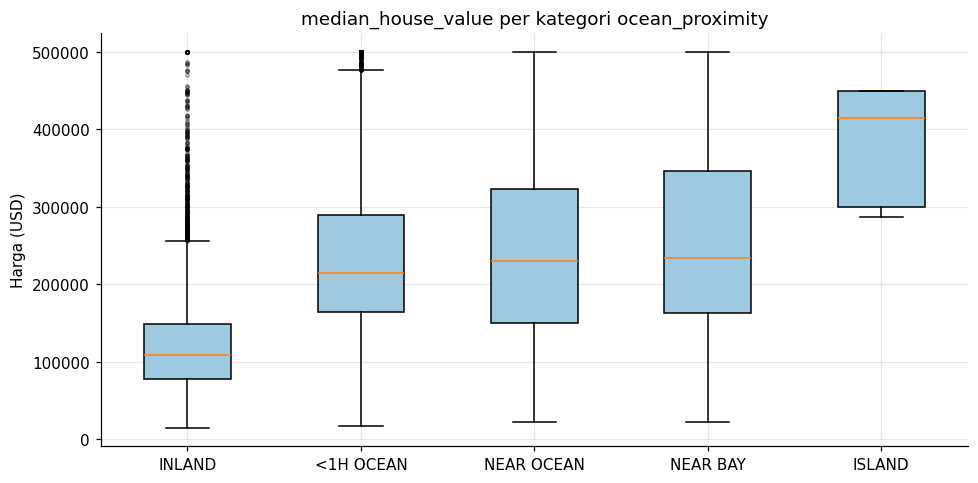

In [ ]:
order = df.groupby(CAT_FEATURE)[TARGET].median().sort_values().index
data = [df.loc[df[CAT_FEATURE] == c, TARGET] for c in order]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(data, patch_artist=True, boxprops={"facecolor": "#9ecae1"},
           flierprops={"markersize": 2, "alpha": 0.4})
ax.set_xticks(range(1, len(order) + 1), list(order))
ax.set(title="median_house_value per kategori ocean_proximity", ylabel="Harga (USD)")
plt.tight_layout()
save_fig("08_harga_per_ocean_proximity")
plt.show()

**Temuan:**
- Hubungan `median_income` dengan harga jelas naik, tetapi terlihat **garis horizontal pada \$500.001**: blok dengan pendapatan
  beragam semuanya terpotong di harga yang sama.
- Peta harga memperlihatkan pola geografis kuat: harga tinggi menumpuk di pesisir (Bay Area dan Los Angeles), harga rendah di pedalaman.
  Pola ini hanya bisa ditangkap bila `latitude` dan `longitude` dipakai bersama, bukan satu per satu.
- Blok `INLAND` jauh lebih murah dibanding kategori lain, jadi `ocean_proximity` informatif.

## 5. Temuan Penting yang Memengaruhi Preprocessing

Tiga pemeriksaan tambahan untuk mendukung keputusan imputasi dan pembuatan fitur baru.

In [ ]:
# 1) Apakah baris dengan total_bedrooms kosong berbeda dari baris lainnya?
cols = [c for c in NUM_FEATURES if c != "total_bedrooms"] + [TARGET]
miss = df[df["total_bedrooms"].isna()]
ok = df[df["total_bedrooms"].notna()]
display(pd.DataFrame({"baris_kosong": miss[cols].mean(), "baris_lengkap": ok[cols].mean()}).round(2))

by_cat = (df.assign(kosong=df["total_bedrooms"].isna())
            .groupby(CAT_FEATURE)["kosong"].agg(jumlah="sum", persen="mean"))
by_cat["persen"] = (by_cat["persen"] * 100).round(2)
display(by_cat)

,baris_kosong,baris_lengkap
longitude,-119.47,-119.57
latitude,35.50,35.63
housing_median_age,29.27,28.63
total_rooms,2562.60,2636.50
population,1477.77,1424.95
households,510.02,499.43
median_income,3.82,3.87
median_house_value,206007.28,206864.41


,jumlah,persen
ocean_proximity,,
<1H OCEAN,102,1.12
INLAND,55,0.84
ISLAND,0,0.00
NEAR BAY,20,0.87
NEAR OCEAN,30,1.13


In [ ]:
# 2) Fitur rasio yang diusulkan (nilai per rumah tangga/kamar lebih bermakna daripada total blok)
ratios = pd.DataFrame({
    "rooms_per_household": df["total_rooms"] / df["households"],
    "bedrooms_per_room": df["total_bedrooms"] / df["total_rooms"],
    "population_per_household": df["population"] / df["households"],
})
display(ratios.describe(percentiles=[0.01, 0.5, 0.99]).T.round(2))
print("Baris dengan households > population :", int((df["households"] > df["population"]).sum()))
print("Baris dengan total_bedrooms > total_rooms:", int((df["total_bedrooms"] > df["total_rooms"]).sum()))

,count,mean,std,min,1%,50%,99%,max
rooms_per_household,20640.0,5.43,2.47,0.85,2.58,5.23,10.36,141.91
bedrooms_per_room,20433.0,0.21,0.06,0.10,0.12,0.20,0.41,1.00
population_per_household,20640.0,3.07,10.39,0.69,1.54,2.82,5.39,1243.33


Baris dengan households > population : 3
Baris dengan total_bedrooms > total_rooms: 0


In [ ]:
# 3) Nilai yang terpotong (capped)
print(f"median_house_value = {df[TARGET].max():,.0f}: {(df[TARGET] == df[TARGET].max()).sum():,} baris "
      f"({(df[TARGET] == df[TARGET].max()).mean() * 100:.2f}%)")
print(f"housing_median_age = {df['housing_median_age'].max():.0f}: "
      f"{(df['housing_median_age'] == df['housing_median_age'].max()).sum():,} baris "
      f"({(df['housing_median_age'] == df['housing_median_age'].max()).mean() * 100:.2f}%)")

median_house_value = 500,001: 965 baris (4.68%)
housing_median_age = 52: 1,273 baris (6.17%)


**Hasil pemeriksaan tambahan:**
- Baris dengan `total_bedrooms` kosong punya rata-rata fitur lain dan harga yang hampir sama dengan baris lengkap, dan proporsi
  kosongnya mirip di setiap kategori (sekitar 1%). Tidak ada tanda bahwa kekosongan terkait wilayah atau harga, sehingga imputasi sederhana aman.
- Fitur rasio punya nilai ekstrem: `population_per_household` mencapai 1.243 padahal persentil ke-99 hanya sekitar 5,4.
  Rasio ini perlu dibatasi (*clip*) atau dilog agar tidak mendominasi.
- Tidak ada baris dengan kamar tidur lebih banyak dari total kamar. Hanya 3 baris dengan rumah tangga lebih banyak dari penduduk.

### Rangkuman temuan dan keputusan preprocessing

| No | Temuan EDA | Bukti | Keputusan preprocessing |
|---|---|---|---|
| 1 | `total_bedrooms` kosong pada 207 baris (1,0%), tampak acak | Bagian 5 | Imputasi **median**, dihitung dari **data train saja** |
| 2 | Empat fitur hitungan sangat miring (skew 3,4 sampai 4,9) | Bagian 3 | Transformasi **`log1p`** (skew turun ke ≈ −1) |
| 3 | Outlier IQR ±6% pada fitur hitungan, tetapi valid | Bagian 3 | **Tidak dihapus**; diredam oleh `log1p` |
| 4 | `ocean_proximity` kategorikal, `ISLAND` hanya 5 baris | Bagian 3 | **One-hot** 5 kategori, `ISLAND` tetap dipertahankan |
| 5 | Skala fitur sangat berbeda (`total_rooms` hingga 39.320, `median_income` 0,5 sampai 15) | Bagian 1 | **StandardScaler**, di-*fit* pada data train saja |
| 6 | Target terpotong di \$500.001 (965 baris), umur terpotong di 52 (1.273 baris) | Bagian 2, 5 | Dipertahankan; dicatat sebagai keterbatasan dan dievaluasi terpisah di notebook evaluasi |
| 7 | Target dalam ratusan ribu USD, miring ke kanan | Bagian 2 | Skala target **÷ 100.000** agar MSE stabil; MAE dilaporkan kembali dalam USD |
| 8 | Empat fitur hitungan saling berkorelasi 0,86 sampai 0,98 | Bagian 4 | Ditambah **fitur rasio** (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`) sebagai eksperimen; regularisasi **L2** membantu |
| 9 | Rasio punya nilai ekstrem (`population_per_household` maks 1.243) | Bagian 5 | **Clip** atau log pada fitur rasio |
| 10 | Pola harga bersifat geografis dan tidak linear | Bagian 4 | Pertahankan `latitude` dan `longitude` bersama; MLP dipilih karena mampu menangkap interaksi nonlinear |
| 11 | Imputasi dan scaling memakai statistik data | – | **Split 70/15/15 dilakukan lebih dulu**, baru imputer dan scaler di-*fit* pada train (mencegah *data leakage*) |

## Kesimpulan

Dataset cukup bersih (hanya 1% nilai kosong, tanpa duplikat) tetapi memerlukan penanganan skewness, nilai terpotong, dan skala fitur.
`median_income` dan lokasi adalah sinyal utama. Langkah berikutnya: **`02_preprocessing.ipynb`**, yang menerapkan keputusan di tabel ini.